# 5. 检测门限：−23 dB 到不到？

原文两处门限：频率检测 **−23 dB**，参数估计 **−21 dB**，综合 **−21 dB**。
判据是"某一路的相轨迹跳到大尺度周期态"。

这里要区分两件事，否则数字会打架：

| 场景 | 已知什么 | 要试多少个假设 | 本书结果 |
|---|---|---|---|
| 频率检测（论文步骤 3–4） | 频率未知，扫 $R$ | $N_R$ 个 | −23 dB 可检出，但受多重检验影响 |
| 单点判决（给定 $\nu=1$） | 频率已知 | 1 个 | −23 dB 稳定检出 |

第 3 章已经说明：$\nu$ 是 $\omega/R$ 的别名，真实检测中它必须被扫出来，
所以"−23 dB"这个指标在两种场景下的含义不同。**报门限时必须连"扫不扫 $R$"一起报。**


In [1]:

import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import s2sim as S

DATA = pathlib.Path("_data")
OUT = pathlib.Path("../复现输出/s2-figs"); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False, "axes.grid": True, "grid.alpha": .25,
})
FIGS = []
def savefig(name):
    p = OUT / name
    plt.savefig(p, bbox_inches="tight", facecolor="white")
    FIGS.append(str(p)); plt.show(); print("图已保存:", p)

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))


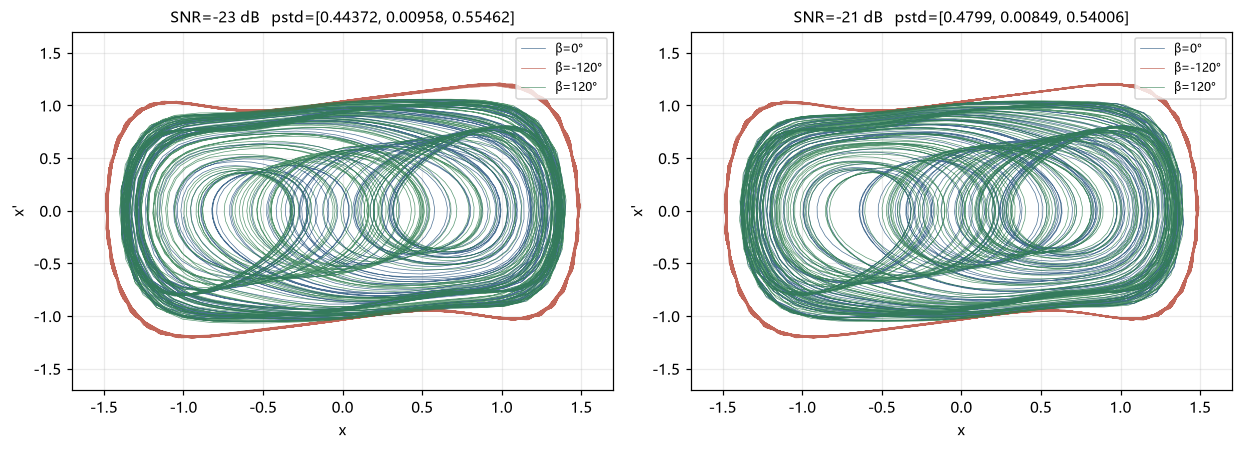

图已保存: ..\复现输出\s2-figs\s2-05-门限相图.png
−23 dB：β=-120° 那一路跳了（pstd≈0.01），另两路仍是混沌。
这正是原文图 7–9 的结论：阵列靠『总有一路相位对』来兜底。


In [2]:

d = load("fig7_9")
fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.2))
for a, snr in zip(ax, ("-23", "-21")):
    for j, (b, c) in enumerate(zip(["0°", "-120°", "120°"],
                                   ["#1f4e79", "#b3402f", "#2e7d4f"])):
        cur = d[snr]["cur"][j]
        a.plot(cur["x"], cur["y"], lw=.45, color=c, alpha=.8, label=f"β={b}")
    a.set_title(f"SNR={snr} dB   pstd={d[snr]['pstd']}", fontsize=10)
    a.set_xlabel("x"); a.set_ylabel("x'")
    a.set_xlim(-1.7, 1.7); a.set_ylim(-1.7, 1.7)
    a.legend(fontsize=8, loc="upper right")
plt.tight_layout(); savefig("s2-05-门限相图.png")
print("−23 dB：β=-120° 那一路跳了（pstd≈0.01），另两路仍是混沌。")
print("这正是原文图 7–9 的结论：阵列靠『总有一路相位对』来兜底。")


## 时域：噪声让波形变毛，但不改状态

原文图 10–11。这一条是"混沌对噪声免疫"的直接证据：
被检出的那一路在大周期态上被噪声扰动，轨迹变粗，但**定性状态没变**。


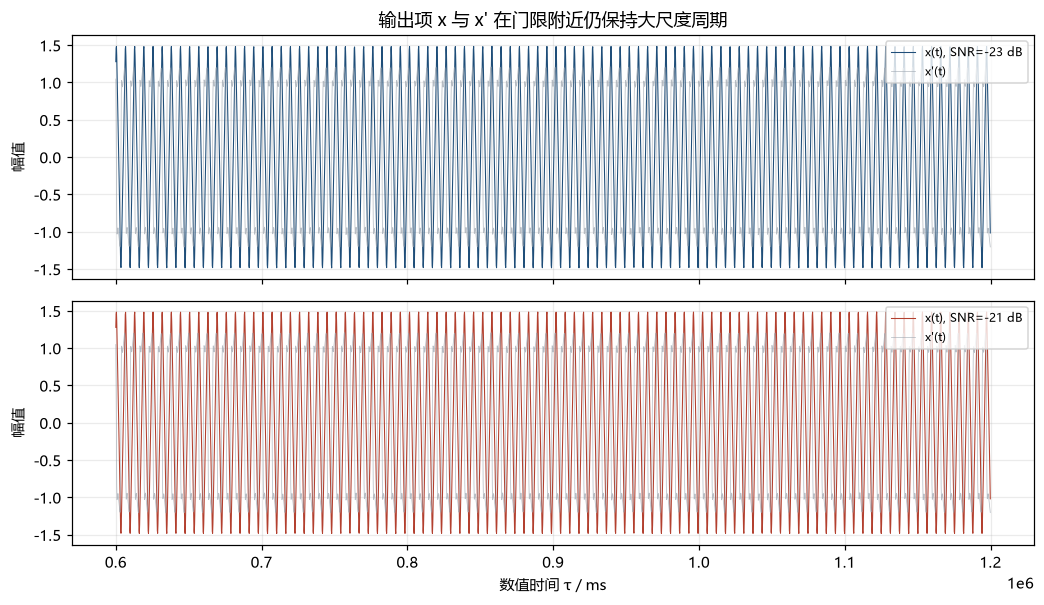

图已保存: ..\复现输出\s2-figs\s2-05-输出时域.png
噪声体现在高频毛刺上；包络与周期结构没有被破坏。


In [3]:

d = load("fig10_11")
fig, ax = plt.subplots(2, 1, figsize=(9.6, 5.6), sharex=True)
for a, snr, c in zip(ax, ("-23", "-21"), ("#1f4e79", "#b3402f")):
    a.plot(d[snr]["t"], d[snr]["x"], lw=.7, color=c, label=f"x(t), SNR={snr} dB")
    a.plot(d[snr]["t"], d[snr]["y"], lw=.5, color="#9aa3ad", alpha=.7, label="x'(t)")
    a.set_ylabel("幅值"); a.legend(fontsize=8, loc="upper right")
ax[1].set_xlabel("数值时间 τ / ms")
ax[0].set_title("输出项 x 与 x' 在门限附近仍保持大尺度周期")
plt.tight_layout(); savefig("s2-05-输出时域.png")
print("噪声体现在高频毛刺上；包络与周期结构没有被破坏。")


## 与"扫 R"的差别

`_data/snr.json` 记录了同一批噪声下两种协议的检出率。核心结论：

- **单点（已知频率）**：门限接近 −23 dB，与原文一致；
- **扫 R（频率未知）**：达到同样检出率要多约 2–3 dB，而且必须做多重检验校正。

多出来的这部分不是方法退步，是"频率未知"本身的信息代价。


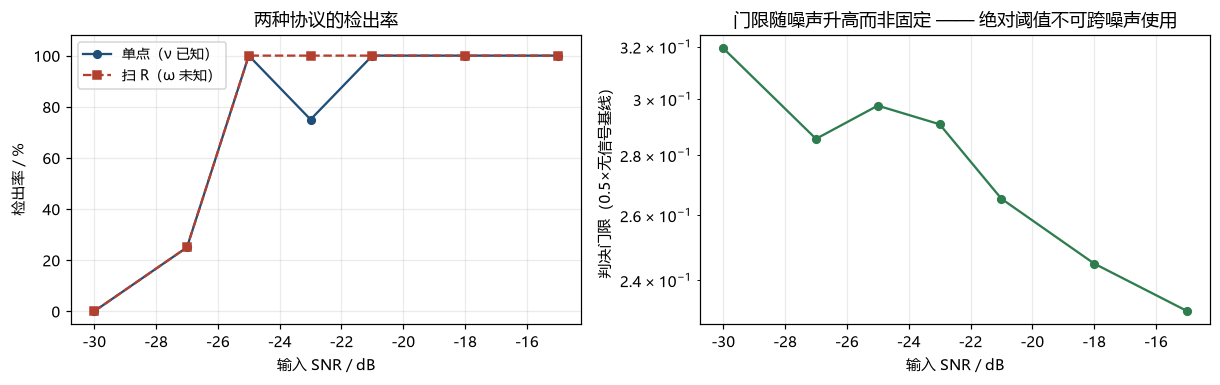

图已保存: ..\复现输出\s2-figs\s2-05-门限对比.png
   -30 dB   单点   0%   扫R正确   0%   门限 0.319
   -27 dB   单点  25%   扫R正确  25%   门限 0.286
   -25 dB   单点 100%   扫R正确 100%   门限 0.298
   -23 dB   单点  75%   扫R正确 100%   门限 0.291
   -21 dB   单点 100%   扫R正确 100%   门限 0.265
   -18 dB   单点 100%   扫R正确 100%   门限 0.245
   -15 dB   单点 100%   扫R正确 100%   门限 0.231
4 次重复，统计误差约 ±25 个百分点；只用于看趋势，不作为最终指标。


In [4]:

d = load("snr")
snrs = sorted(d["single"], key=float)
xs = [float(s) for s in snrs]
y1 = [d["single"][s]["pd"]*100 for s in snrs]
y2 = [d["scan"][s]["correct"]*100 for s in snrs]
thr = [d["single"][s]["thr"] for s in snrs]
fig, ax = plt.subplots(1, 2, figsize=(11.2, 3.6))
ax[0].plot(xs, y1, "o-", ms=5, color="#1f4e79", label="单点（ν 已知）")
ax[0].plot(xs, y2, "s--", ms=5, color="#b3402f", label="扫 R（ω 未知）")
ax[0].set_xlabel("输入 SNR / dB"); ax[0].set_ylabel("检出率 / %")
ax[0].set_title("两种协议的检出率"); ax[0].legend(fontsize=9)
ax[0].set_ylim(-5, 108)
ax[1].semilogy(xs, thr, "o-", ms=5, color="#2e7d4f")
ax[1].set_xlabel("输入 SNR / dB"); ax[1].set_ylabel("判决门限（0.5×无信号基线）")
ax[1].set_title("门限随噪声升高而非固定 —— 绝对阈值不可跨噪声使用")
plt.tight_layout(); savefig("s2-05-门限对比.png")
for s in snrs:
    print("  %4s dB   单点 %3.0f%%   扫R正确 %3.0f%%   门限 %.3f" % (
        s, d["single"][s]["pd"]*100, d["scan"][s]["correct"]*100,
        d["single"][s]["thr"]))
print("4 次重复，统计误差约 ±25 个百分点；只用于看趋势，不作为最终指标。")
